##<font color='Maroon'>Telco Customer Churn using TensorFlow <b>Decision Forests</b></font>

*Based on Algirdas Laukaitis' "AdventureWorks DW using TensorFlow Decision Forests" notebook, re-done with different data.*

**What changed compared with the original notebook**

| | Original | This notebook |
|---|---|---|
| Data | AdventureWorks DW `vTargetMail`: 18,484 customers of a bike shop | **IBM Telco Customer Churn: 7,043 customers of a phone and internet company** |
| Question | Will this customer buy a bike? (`BikeBuyer`) | **Will this customer leave the company?** (`Churn`) |
| Features | age, income, children, cars, education, region… | contract type, months as a customer, monthly bill, internet service, payment method… |
| Classes | about 50% buyers | about 27% leave, so "always guess *stays*" already scores ~73% |

[Dataset source on GitHub (IBM)](https://github.com/IBM/telco-customer-churn-on-icp4d)

<br><br>

---
#<font color='Maroon'>Step 1. From a csv data file that is available online to 2 DataFrame tables: training and test</font>

## 1.1 Let's load the Telco Customer Churn csv data into a dataframe from GitHub.

In [2]:
import pandas as pd
df_all_col = pd.read_csv('https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv')
print("The dataframe has {} rows and {} columns.".format(df_all_col.shape[0], df_all_col.shape[1]))

The dataframe has 7043 rows and 21 columns.


## 1.2 Next, we examine the first rows of the data to decide which information is relevant to our task.

In [3]:
df_all_col[0:5]

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1.3 We remove attributes that we don't require and prepare the label
> *The label column is renamed to `target`, as in the original notebook, so the rest of the code stays the same.*

In [4]:
df = df_all_col.copy()

df.drop(columns=["customerID"], inplace=True)          # an ID tells nothing about behaviour

# TotalCharges is read as text because 11 brand-new customers (tenure = 0 months) have it blank.
# Convert to numbers; those 11 have not paid anything yet, so their total is 0.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# The label must be a number: 1 = customer left (churned), 0 = stayed. Renamed to 'target' like in the original.
df["target"] = (df.pop("Churn") == "Yes").astype(int)

print(df.iloc[0])
print('---------------')
print(df.dtypes)

gender                        Female
SeniorCitizen                      0
Partner                          Yes
Dependents                        No
tenure                             1
PhoneService                      No
MultipleLines       No phone service
InternetService                  DSL
OnlineSecurity                    No
OnlineBackup                     Yes
DeviceProtection                  No
TechSupport                       No
StreamingTV                       No
StreamingMovies                   No
Contract              Month-to-month
PaperlessBilling                 Yes
PaymentMethod       Electronic check
MonthlyCharges                 29.85
TotalCharges                   29.85
target                             0
Name: 0, dtype: object
---------------
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      obje

In [5]:
#@title How many customers leave?
churn_rate = df["target"].mean()
print(f"{churn_rate:.1%} of customers left, {1 - churn_rate:.1%} stayed.")
print(f"A model that always answers 'stays' would already be {1 - churn_rate:.1%} accurate -> this is the baseline to beat.")

26.5% of customers left, 73.5% stayed.
A model that always answers 'stays' would already be 73.5% accurate -> this is the baseline to beat.


## 1.4 Split the DataFrame into training and test sets

When we teach a machine learning model, we want to make sure it can perform well on new data that it has not seen before. To do this, we typically divide our data into three sets: the training set, the validation set, and the test set.

The training set is used to teach the model how to make predictions. The validation set is used to fine-tune the model and to notice overfitting (the model memorising the training data instead of learning general rules). The test set is used to check how well the model performs on new data after it has been trained. (But for Decision Forests we don't need a validation set: each tree is checked on the customers it did not see during its training, the so-called *out-of-bag* data.)

In [6]:
import numpy as np

shuffled = df.sample(frac=1, random_state=42)          # shuffle rows; random_state makes the split repeatable
cut = int(0.9 * len(shuffled))                          # 90:10 ratio
train, test = shuffled.iloc[:cut], shuffled.iloc[cut:]
print(len(train), 'training examples')
print(len(test), 'test examples')

6338 training examples
705 test examples


<br><br>

---
#<font color='Maroon'>Step 2. From DataFrame table to TensorFlow dataset data</font>

## Import TensorFlow and other libraries

In [7]:
!pip install tensorflow_decision_forests

In [8]:
import tensorflow_decision_forests as tfdf

train_ds = tfdf.keras.pd_dataframe_to_tf_dataset(train, label='target')
test_ds = tfdf.keras.pd_dataframe_to_tf_dataset(test, label='target')

<br><br>

---
#<font color='Maroon'>Step 3. Model</font>

A random forest is many decision trees, each trained on a random part of the data. Every tree votes and the forest returns the share of votes for "leaves".
Unlike a neural network, it needs **no preprocessing**: text columns such as `Contract` are used as they are, and numbers need no normalisation.

In [9]:
model_1 = tfdf.keras.RandomForestModel(num_trees=100, max_depth=15)  # 100 trees, each at most 15 questions deep

Use /tmp/tmpp3qygmma as temporary training directory


<br><br>

---
#<font color='Maroon'>Step 4. Train and evaluate the model</font>

<br>

##<font color='Maroon'>Train 🏃‍♂️</font>

In [10]:
model_1.fit(train_ds)

Reading training dataset...
Training dataset read in 0:00:05.716970. Found 6338 examples.
Training model...
Model trained in 0:00:02.106843
Compiling model...
Model compiled.


<br>

##<font color='Maroon'>Evaluate ⚖️</font>

In [11]:
model_1.compile(metrics=['accuracy'])
evaluation = model_1.evaluate(test_ds, return_dict=True)
print(f'Test accuracy: {evaluation["accuracy"]:.4f}')
print(f'Baseline (always "stays"): {1 - test["target"].mean():.4f}')

1/1 [==============================] - 1s 1s/step - loss: 0.0000e+00 - accuracy: 0.7972
Test accuracy: 0.7972
Baseline (always "stays"): 0.7574


<br>

##<font color='Maroon'>Plotting the training logs 🧾</font>

How accuracy changes as more trees are added to the forest.

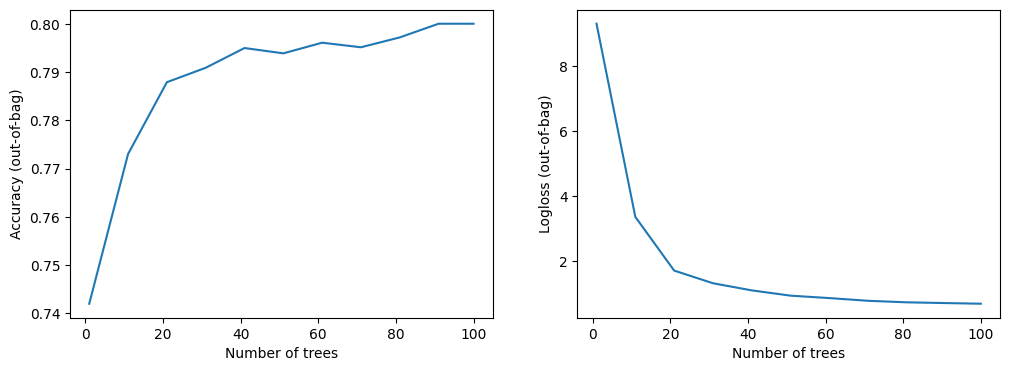

In [12]:
import matplotlib.pyplot as plt

logs = model_1.make_inspector().training_logs()

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot([log.num_trees for log in logs], [log.evaluation.accuracy for log in logs])
plt.xlabel("Number of trees")
plt.ylabel("Accuracy (out-of-bag)")

plt.subplot(1, 2, 2)
plt.plot([log.num_trees for log in logs], [log.evaluation.loss for log in logs])
plt.xlabel("Number of trees")
plt.ylabel("Logloss (out-of-bag)")

plt.show()

<br>

##<font color='Maroon'>Which features matter most? 📊</font>

`NUM_AS_ROOT` counts how many of the 100 trees ask about this feature first, at the very top of the tree.

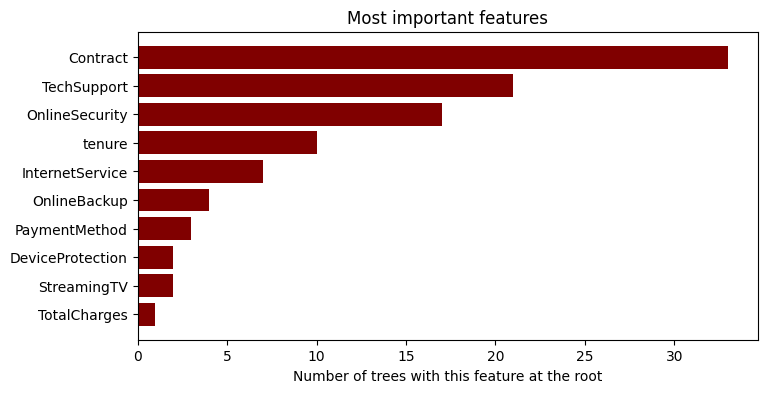

In [13]:
importances = model_1.make_inspector().variable_importances()["NUM_AS_ROOT"]
names = [imp[0].name for imp in importances]
values = [imp[1] for imp in importances]

plt.figure(figsize=(8, 4))
plt.barh(names[::-1], values[::-1], color='maroon')
plt.xlabel("Number of trees with this feature at the root")
plt.title("Most important features")
plt.show()

<br>

##<font color='Maroon'>Let's choose one tree 🌲 from the forest (tree_idx=...) and plot the model</font>

In [14]:
tfdf.model_plotter.plot_model_in_colab(model_1, tree_idx=0, max_depth=4)  ## max_depth=4 shows the top 4 levels so the tree stays readable

<br><br>

---
#<font color='Maroon'> Step 5. Perform inference 🛠</font>

##<font color='Maroon'> Save 💾 </font>

In [15]:
model_1.save('Telco_Churn_RandomForestModel_trees100')

##<font color='Maroon'> Load ⚙️</font>

In [16]:
import tensorflow as tf
reloaded_model = tf.keras.layers.TFSMLayer('Telco_Churn_RandomForestModel_trees100', call_endpoint='serving_default')

##<font color='Maroon'> New data  🗃️</font>

Two made-up customers: a new one on a month-to-month contract, and a long-time customer on a two-year contract.

In [17]:
samples = pd.DataFrame([
    {   # new customer, month-to-month, fiber internet, no extras, pays by electronic check
        'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No',
        'tenure': 3, 'PhoneService': 'Yes', 'MultipleLines': 'No',
        'InternetService': 'Fiber optic', 'OnlineSecurity': 'No', 'OnlineBackup': 'No',
        'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'Yes', 'StreamingMovies': 'Yes',
        'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check',
        'MonthlyCharges': 95.0, 'TotalCharges': 285.0,
    },
    {   # loyal customer, 5 years, two-year contract, automatic card payment
        'gender': 'Male', 'SeniorCitizen': 0, 'Partner': 'Yes', 'Dependents': 'Yes',
        'tenure': 60, 'PhoneService': 'Yes', 'MultipleLines': 'Yes',
        'InternetService': 'DSL', 'OnlineSecurity': 'Yes', 'OnlineBackup': 'Yes',
        'DeviceProtection': 'Yes', 'TechSupport': 'Yes', 'StreamingTV': 'No', 'StreamingMovies': 'No',
        'Contract': 'Two year', 'PaperlessBilling': 'No', 'PaymentMethod': 'Credit card (automatic)',
        'MonthlyCharges': 70.0, 'TotalCharges': 4200.0,
    },
])
samples

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,No,No,3,Yes,No,Fiber optic,No,No,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,95.0,285.0
1,Male,0,Yes,Yes,60,Yes,Yes,DSL,Yes,Yes,Yes,Yes,No,No,Two year,No,Credit card (automatic),70.0,4200.0


##<font color='Maroon'> Predict  🔮</font>

In [18]:
new_observation_ds = tfdf.keras.pd_dataframe_to_tf_dataset(samples)
predictions = model_1.predict(new_observation_ds)

for i, p in enumerate(predictions[:, 0]):
    print(f"Customer {i + 1}: probability of leaving = {p:.1%}")

1/1 [==============================] - 0s 162ms/step
Customer 1: probability of leaving = 75.0%
Customer 2: probability of leaving = 0.0%


<br><br><br>

---
---

#<font color='Maroon'> Visualizing TensorFlow Decision Forest Trees with dtreeviz</font>

In [19]:
%%capture
!pip install -q -U dtreeviz

In [20]:
import dtreeviz
import logging
logging.getLogger('matplotlib.font_manager').setLevel(level=logging.CRITICAL)  # avoid "Arial font not found" warnings

## Display decision tree

If your installed versions of dtreeviz and TF-DF don't work together, this cell prints a message instead of failing. The tree plot above already shows the same tree.

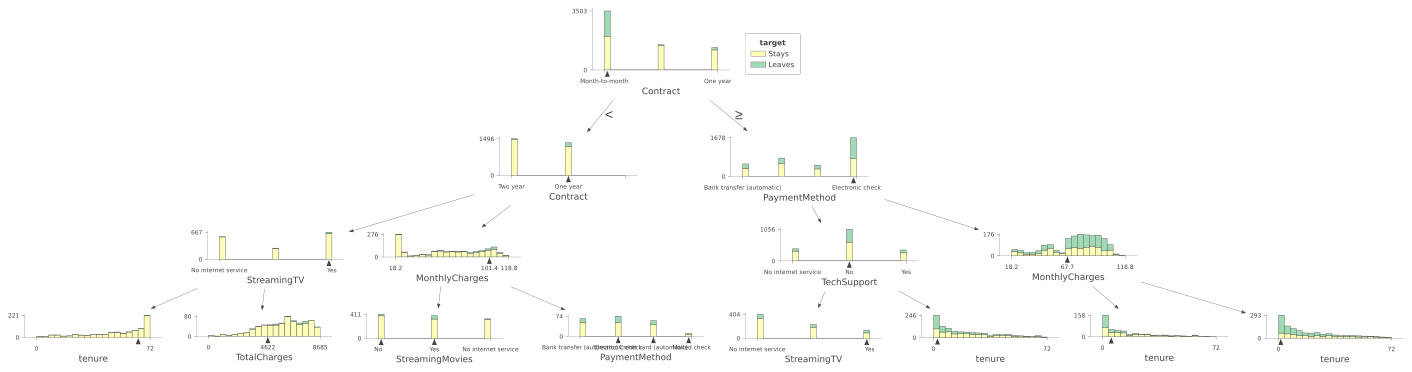

In [21]:
features = [f.name for f in model_1.make_inspector().features()]
try:
    viz_cmodel = dtreeviz.model(model_1,
                                tree_index=0,
                                X_train=train[features],
                                y_train=train['target'],
                                feature_names=features,
                                target_name='target',
                                class_names=['Stays', 'Leaves'])
    display(viz_cmodel.view(depth_range_to_display=(0, 3), scale=1.0))
except Exception as e:
    print("dtreeviz could not draw this model:", e)

<br><br>

---
#<font color='Maroon'>Conclusions</font>

* **The random forest reached 79.7% test accuracy**, against a baseline of 75.7% (always guessing "stays"), an improvement of about 4 percentage points. Most customers stay anyway, so this is a harder task than it first seems.
* **The predictions make sense:** the new month-to-month customer has a **75.0%** chance of leaving, and the 5-year customer on a two-year contract **0%** (none of the 100 trees voted "leaves").
* The forest worked directly on the raw table: text columns such as `Contract` and numbers such as `MonthlyCharges` were used as they are, with no encoding or normalisation.
* **Compared with the neural network on the same data** (79.3%), the forest is slightly better, but the gap (0.4 percentage points, about 3 customers out of 705) is too small to matter. Both models agree on which customers are at risk.